In [ ]:
import pandas as pd

# Column names
column_names = [
    "status", "duration", "credit_history", "purpose", "credit_amount",
    "savings", "employment", "installment_rate", "personal_status",
    "other_debtors", "residence_since", "property", "age", "other_plans",
    "housing", "existing_credits", "job", "dependents", "telephone",
    "foreign_worker", "credit_outcome"
]

# Load directly from UCI (NO uploading)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"

df = pd.read_csv(url, sep=" ", names=column_names)

print(df.shape)
df.head()

(1000, 21)


,status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_outcome
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [ ]:
df.shape

(1000, 21)

In [ ]:
df.head()

,status,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,credit_outcome
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [ ]:
df["age_group"] = df["age"].apply(lambda x: "under_30" if x < 30 else "30_and_above")

df["age_group"].value_counts()


,count
age_group,
30_and_above,629
under_30,371


In [ ]:
df["credit_outcome_binary"] = df["credit_outcome"].apply(lambda x: 1 if x == 1 else 0)

df["credit_outcome_binary"].value_counts()


,count
credit_outcome_binary,
1,700
0,300


In [ ]:
features = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since",
    "age"
]

X = df[features]
y = df["credit_outcome_binary"]


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
# Model coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

print(coefficients)

            Feature  Coefficient
0          duration    -0.021393
1     credit_amount    -0.000086
2  installment_rate    -0.185635
3   residence_since    -0.074878
4               age     0.034770


In [ ]:
# Remove age and retrain
features_no_age = [
    "duration",
    "credit_amount",
    "installment_rate",
    "residence_since"
]

X2 = df[features_no_age]
y2 = df["credit_outcome_binary"]

from sklearn.model_selection import train_test_split

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X2, y2, test_size=0.3, random_state=42, stratify=y2
)

from sklearn.linear_model import LogisticRegression

model2 = LogisticRegression(max_iter=1000)
model2.fit(X_train2, y_train2)

y_pred2 = model2.predict(X_test2)

In [ ]:
coefficients_no_age = pd.DataFrame({
    "Feature": X2.columns,  # X2 is your age-removed feature set
    "Coefficient": model2.coef_[0]
})
print(coefficients_no_age)

            Feature  Coefficient
0          duration    -0.029104
1     credit_amount    -0.000053
2  installment_rate    -0.109467
3   residence_since    -0.007454


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.7233333333333334
Confusion Matrix:
 [[ 10  81]
 [  2 207]]


In [ ]:
X_test = X_test.copy()
X_test["actual"] = y_test
X_test["predicted"] = y_pred
X_test["age_group"] = df.loc[X_test.index, "age_group"]

In [ ]:
X_test2 = X_test2.copy()
X_test2["actual"] = y_test2
X_test2["predicted"] = y_pred2
X_test2["age_group"] = df.loc[X_test2.index, "age_group"]

In [ ]:
def calculate_error_rates(group):
    TP = ((group["actual"] == 1) & (group["predicted"] == 1)).sum()
    TN = ((group["actual"] == 0) & (group["predicted"] == 0)).sum()
    FP = ((group["actual"] == 0) & (group["predicted"] == 1)).sum()
    FN = ((group["actual"] == 1) & (group["predicted"] == 0)).sum()

    return pd.Series({
        "accuracy": (TP + TN) / len(group),
        "false_positive_rate": FP / (FP + TN) if (FP + TN) > 0 else 0,
        "false_negative_rate": FN / (FN + TP) if (FN + TP) > 0 else 0
    })

In [ ]:
results = X_test.groupby("age_group")[["actual", "predicted"]].apply(calculate_error_rates)
print(results)

              accuracy  false_positive_rate  false_negative_rate
age_group                                                       
30_and_above  0.709845             0.964912             0.007353
under_30      0.747664             0.764706             0.013699


In [ ]:
results_no_age = X_test2.groupby("age_group")[["actual", "predicted"]].apply(calculate_error_rates)
print(results_no_age)

              accuracy  false_positive_rate  false_negative_rate
age_group                                                       
30_and_above  0.721053                0.900             0.057143
under_30      0.654545                0.925             0.014286


In [ ]:
from statsmodels.stats.proportion import proportions_ztest

under_30 = X_test[X_test["age_group"] == "under_30"]
above_30 = X_test[X_test["age_group"] == "30_and_above"]

fp_under = ((under_30["actual"] == 0) & (under_30["predicted"] == 1)).sum()
fp_above = ((above_30["actual"] == 0) & (above_30["predicted"] == 1)).sum()

n_under = (under_30["actual"] == 0).sum()
n_above = (above_30["actual"] == 0).sum()

stat, p_value = proportions_ztest([fp_under, fp_above], [n_under, n_above])

print("p-value:", p_value)

p-value: 0.0031352823547528986


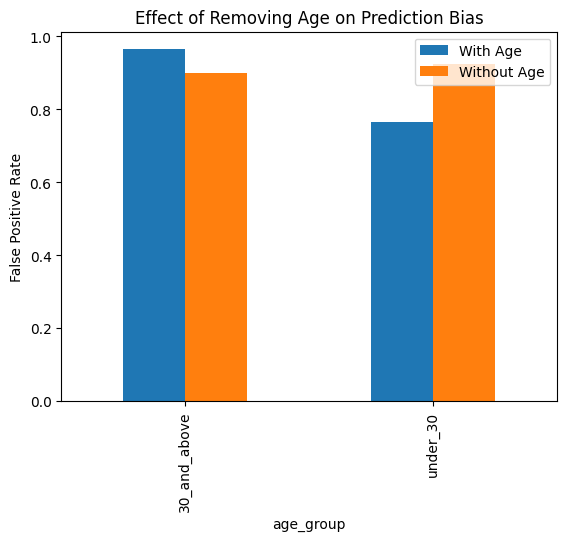

In [ ]:
import matplotlib.pyplot as plt

results_combined = pd.DataFrame({
    "With Age": results["false_positive_rate"],
    "Without Age": results_no_age["false_positive_rate"]
})

results_combined.plot(kind="bar")
plt.ylabel("False Positive Rate")
plt.title("Effect of Removing Age on Prediction Bias")
plt.show()

In [ ]:
# Only keep the features used in training
features = ["duration", "credit_amount", "installment_rate", "residence_since", "age"]

X_test_clean = X_test[features].copy()

In [ ]:
y_pred = model.predict(X_test_clean)

In [ ]:
# Make a new DataFrame for analysis
X_test_analysis = X_test_clean.copy()
X_test_analysis["actual"] = y_test
X_test_analysis["predicted"] = y_pred
X_test_analysis["age_group"] = df.loc[X_test_analysis.index, "age_group"]

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

def calculate_additional_metrics(group):
    precision = precision_score(group["actual"], group["predicted"])
    recall = recall_score(group["actual"], group["predicted"])
    f1 = f1_score(group["actual"], group["predicted"])
    return pd.Series({
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    })

# Only pass the columns needed for calculation to apply(), avoid warning
metrics_by_age = X_test_analysis.groupby("age_group")[["actual", "predicted"]].apply(calculate_additional_metrics)

print("Precision, Recall, F1 by Age Group:\n", metrics_by_age)

Precision, Recall, F1 by Age Group:
               precision    recall  f1_score
age_group                                  
30_and_above   0.710526  0.992647  0.828221
under_30       0.734694  0.986301  0.842105


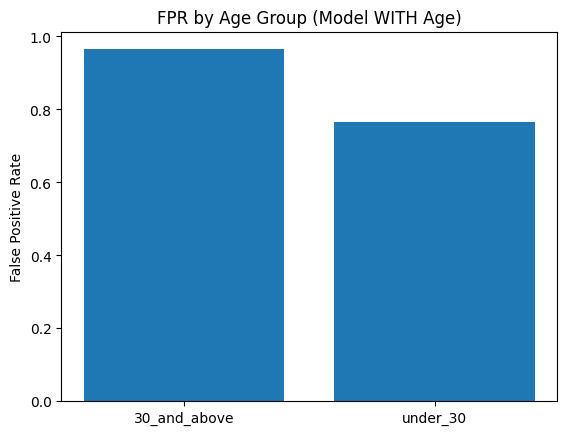

In [ ]:
import matplotlib.pyplot as plt

fpr_with_age = [0.9649, 0.7647]
labels = ["30_and_above", "under_30"]

plt.bar(labels, fpr_with_age)
plt.ylabel("False Positive Rate")
plt.title("FPR by Age Group (Model WITH Age)")
plt.show()

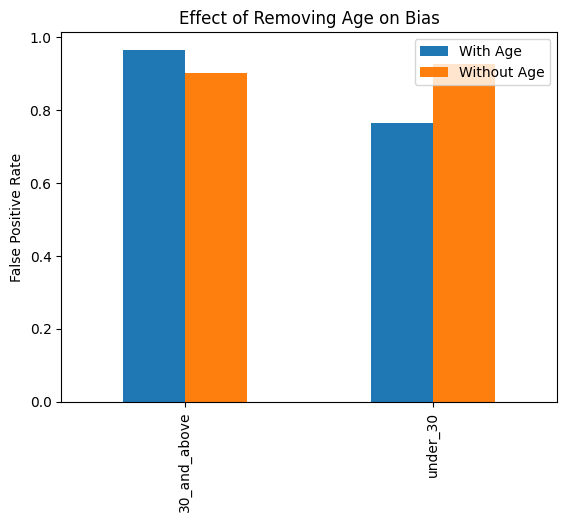

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({
    "With Age": [0.9649, 0.7647],
    "Without Age": [0.900, 0.925]
}, index=["30_and_above", "under_30"])

data.plot(kind="bar")
plt.ylabel("False Positive Rate")
plt.title("Effect of Removing Age on Bias")
plt.show()

In [ ]:
model_age = LogisticRegression(max_iter=1000)
model_age.fit(X_train, y_train)

coef_age = pd.Series(model_age.coef_[0], index=features)

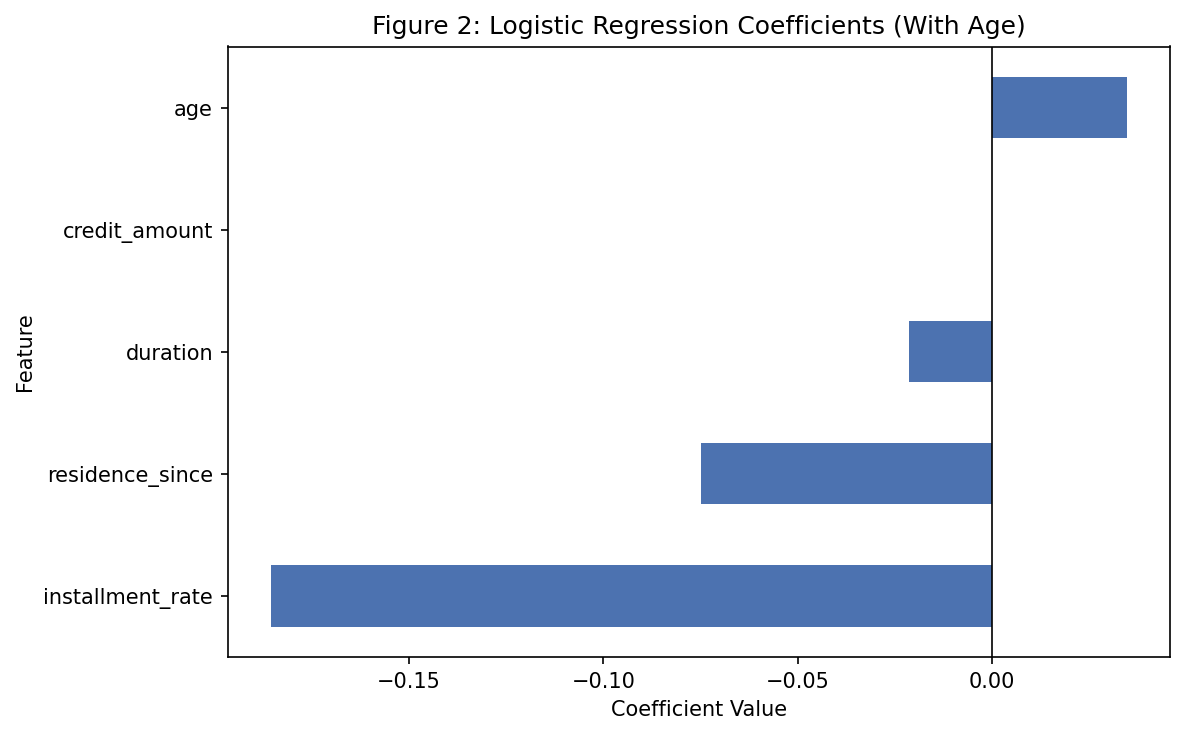

In [ ]:
plt.figure(figsize=(8,5), dpi=150)

coef_age.sort_values().plot(kind="barh", color="#4C72B0")

plt.title("Figure 2: Logistic Regression Coefficients (With Age)", fontsize=12)
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")

plt.axvline(x=0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({
    "font.size": 12,
    "figure.dpi": 150
})

In [ ]:
df = pd.read_csv(url, sep=" ", names=column_names)

In [ ]:
fig1 = df[["duration", "credit_amount", "installment_rate", "residence_since", "age", "credit_outcome"]].head(10)
fig1

,duration,credit_amount,installment_rate,residence_since,age,credit_outcome
0,6,1169,4,4,67,1
1,48,5951,2,2,22,2
2,12,2096,2,3,49,1
3,42,7882,2,4,45,1
4,24,4870,3,4,53,2
5,36,9055,2,4,35,1
6,24,2835,3,4,53,1
7,36,6948,2,2,35,1
8,12,3059,2,4,61,1
9,30,5234,4,2,28,2


In [ ]:
fig1.to_csv("figure1_sample_data.csv", index=False)

In [ ]:
df["age_group"] = df["age"].apply(lambda x: "under_30" if x < 30 else "30_and_above")

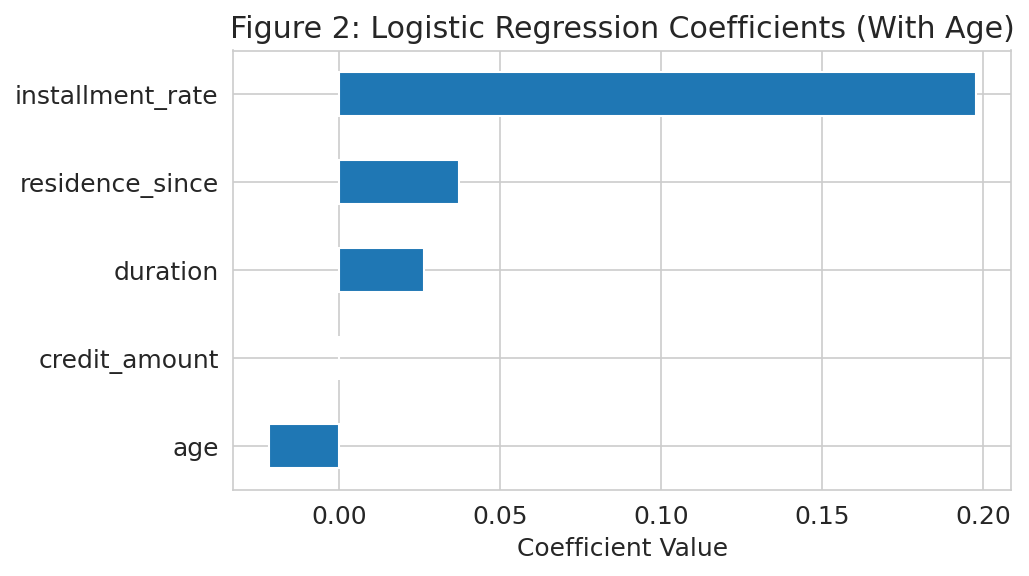

In [ ]:
from sklearn.linear_model import LogisticRegression

features_with_age = ["duration", "credit_amount", "installment_rate", "residence_since", "age"]

X = df[features_with_age]
y = df["credit_outcome"]

model_with_age = LogisticRegression(max_iter=1000)
model_with_age.fit(X, y)

coef_age = pd.Series(model_with_age.coef_[0], index=features_with_age)

plt.figure(figsize=(7,4))
coef_age.sort_values().plot(kind="barh")
plt.title("Figure 2: Logistic Regression Coefficients (With Age)")
plt.xlabel("Coefficient Value")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

df["pred_with_age"] = model_with_age.predict(X)

In [ ]:
def get_rates(group):
    subset = df[df["age_group"] == group]
    tn, fp, fn, tp = confusion_matrix(subset["credit_outcome"], subset["pred_with_age"]).ravel()
    fpr = fp / (fp + tn)
    fnr = fn / (fn + tp)
    return fpr, fnr

groups = ["under_30", "30_and_above"]

fpr = []
fnr = []

for g in groups:
    fpr_val, fnr_val = get_rates(g)
    fpr.append(fpr_val)
    fnr.append(fnr_val)

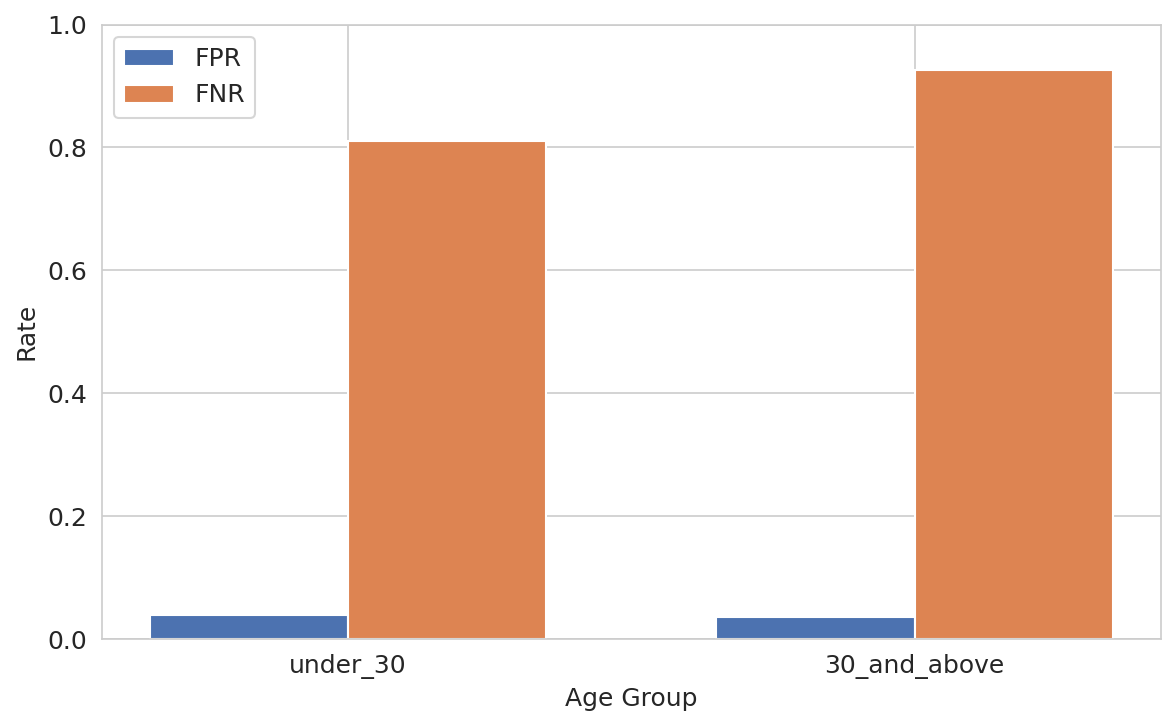

In [ ]:
plt.figure(figsize=(8,5), dpi=150)

x = np.arange(len(groups))
width = 0.35

plt.bar(x - width/2, fpr, width, label="FPR", color="#4C72B0")
plt.bar(x + width/2, fnr, width, label="FNR", color="#DD8452")

plt.xticks(x, groups)
plt.ylabel("Rate")
plt.xlabel("Age Group")

plt.ylim(0, 1)

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
features_no_age = ["duration", "credit_amount", "installment_rate", "residence_since"]

X2 = df[features_no_age]

model_no_age = LogisticRegression(max_iter=1000)
model_no_age.fit(X2, y)

df["pred_no_age"] = model_no_age.predict(X2)

In [ ]:
def fpr_only(group, pred_col):
    subset = df[df["age_group"] == group]
    tn, fp, fn, tp = confusion_matrix(subset["credit_outcome"], subset[pred_col]).ravel()
    return fp / (fp + tn)

fpr_with_age = [fpr_only("30_and_above", "pred_with_age"),
                fpr_only("under_30", "pred_with_age")]

fpr_no_age = [fpr_only("30_and_above", "pred_no_age"),
              fpr_only("under_30", "pred_no_age")]

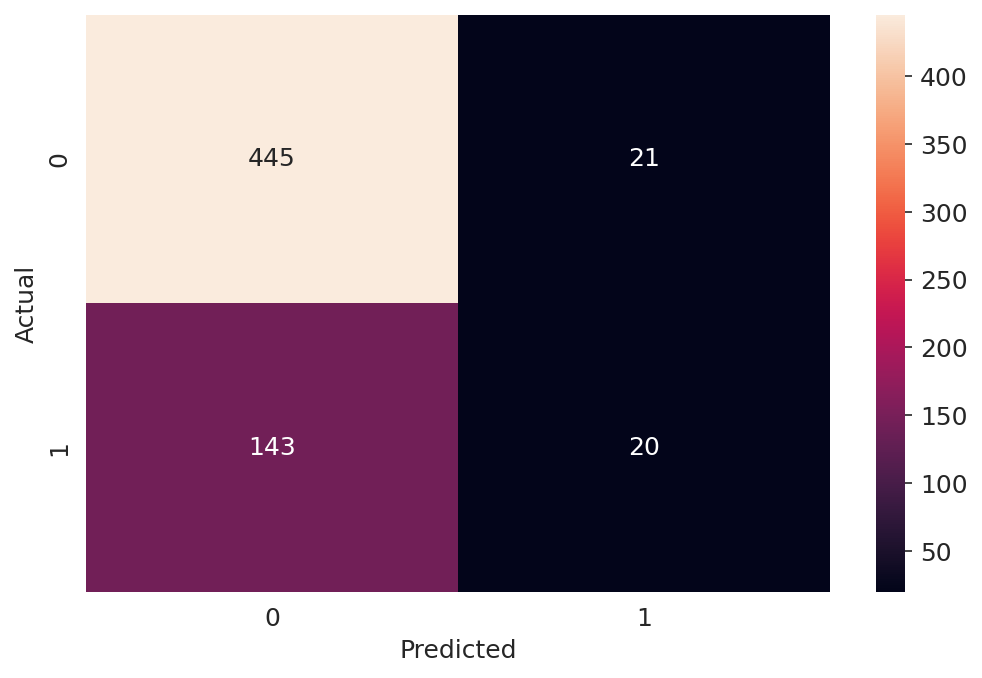

In [ ]:
import seaborn as sns

subset = df[df["age_group"] == "30_and_above"]

cm = confusion_matrix(subset["credit_outcome"], subset["pred_no_age"])

plt.figure(figsize=(8,5), dpi=150)
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()